# Dimension Reduction Techniques — Python companion
**Machine Learning for Biomedical Data (MLBD), Week 4**

This notebook follows the R lecture `lectures/week4/dimensionReduction.Rmd` section by section, replacing `prcomp` with scikit-learn's `PCA`, `svd` with `numpy.linalg.svd`, `NMF::nmf` with `sklearn.decomposition.NMF`, `Rtsne` with `sklearn.manifold.TSNE`, and `uwot::umap` with the `umap-learn` package.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA, NMF
from sklearn.manifold import TSNE
from scipy.spatial.distance import pdist, squareform
import warnings
warnings.filterwarnings("ignore", message="n_jobs value")

## Twin heights
Simulated heights for 100 pairs of twins, 50 adult pairs and 50 child pairs. (Python and R use different random number generators, so the numbers differ slightly from the slides.)

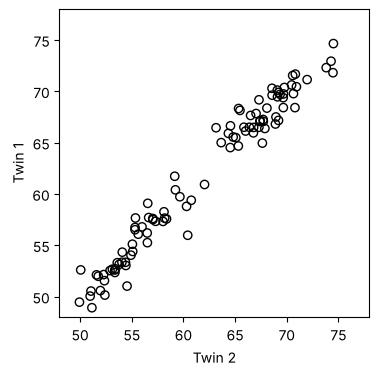

In [2]:
rng = np.random.default_rng(1988)
n = 100
Sigma = np.array([[9, 9 * 0.9], [9 * 0.92, 9]])
Sigma = (Sigma + Sigma.T) / 2          # R's mvrnorm uses the symmetric part
x = np.vstack([rng.multivariate_normal([69, 69], Sigma, n // 2),
               rng.multivariate_normal([55, 55], Sigma, n // 2)])

lim = (48, 78)
plt.figure(figsize=(4, 4))
plt.scatter(x[:, 0], x[:, 1], facecolors="none", edgecolors="k")
plt.xlim(lim); plt.ylim(lim); plt.xlabel("Twin 2"); plt.ylabel("Twin 1")
plt.show()

The average and the difference: most of the distance between points is in the first dimension.

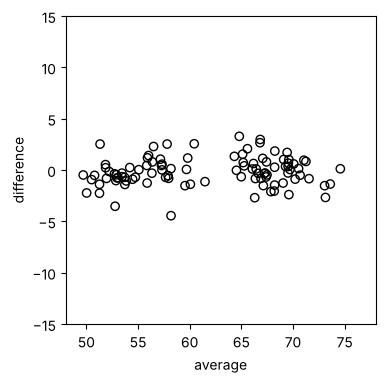

In [3]:
z = np.column_stack([(x[:, 1] + x[:, 0]) / 2, x[:, 1] - x[:, 0]])
plt.figure(figsize=(4, 4))
plt.scatter(z[:, 0], z[:, 1], facecolors="none", edgecolors="k")
plt.xlim(lim); plt.ylim(np.array(lim) - np.mean(lim))
plt.xlabel("average"); plt.ylabel("difference")
plt.show()

## Linear transformations
$Z = XA$, and back again with $X = ZA^{-1}$. In numpy, `@` is matrix multiplication (R's `%*%`).

In [4]:
A = np.array([[1/2, 1], [1/2, -1]])
z = x @ A
x_back = z @ np.linalg.inv(A)
np.abs(x - x_back).max()

np.float64(1.4210854715202004e-14)

## Principal component analysis
`PCA().fit(x)` is `prcomp(x)`:

| R `prcomp` | scikit-learn `PCA` |
|---|---|
| `pca$rotation` | `pca.components_.T` |
| `pca$x` | `pca.transform(x)` |
| `pca$sdev^2` | `pca.explained_variance_` |

The signs of the PCs are arbitrary, so they may be flipped relative to R.

In [5]:
pca = PCA().fit(x)
pd.DataFrame(pca.components_.T, columns=["PC1", "PC2"])

,PC1,PC2
0,0.700780,0.713378
1,0.713378,-0.700780


In [6]:
pcs = pca.transform(x)
pd.DataFrame(np.column_stack([z, pcs]), columns=["average", "difference", "PC1", "PC2"]).head(3)

,average,difference,PC1,PC2
0,67.428564,-0.803452,8.270512,-0.580221
1,71.051664,-0.965422,13.395166,-0.649104
2,66.356999,0.819504,6.744927,0.553837


## Iris example

In [7]:
iris = load_iris(as_frame=True)
X = iris.data.to_numpy()
species = iris.target_names[iris.target]
iris.data.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


Distances between flowers, like `image(as.matrix(dist(x)))`:

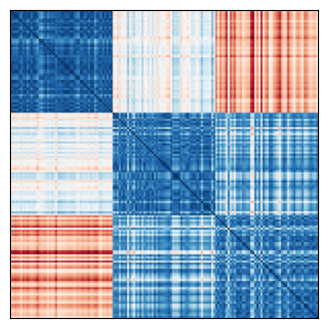

In [8]:
d = squareform(pdist(X))
plt.figure(figsize=(4, 4))
plt.imshow(d, cmap="RdBu_r")
plt.xticks([]); plt.yticks([])
plt.show()

In [9]:
iris.data.corr().round(2)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.00,-0.12,0.87,0.82
sepal width (cm),-0.12,1.00,-0.43,-0.37
petal length (cm),0.87,-0.43,1.00,0.96
petal width (cm),0.82,-0.37,0.96,1.00


Variance explained, like `summary(prcomp(x))`:

In [10]:
pca = PCA().fit(X)
pd.DataFrame({"Standard deviation": np.sqrt(pca.explained_variance_),
              "Proportion of Variance": pca.explained_variance_ratio_,
              "Cumulative Proportion": np.cumsum(pca.explained_variance_ratio_)},
             index=[f"PC{i+1}" for i in range(4)]).T.round(4)

,PC1,PC2,PC3,PC4
Standard deviation,2.0563,0.4926,0.2797,0.1544
Proportion of Variance,0.9246,0.0531,0.0171,0.0052
Cumulative Proportion,0.9246,0.9777,0.9948,1.0000


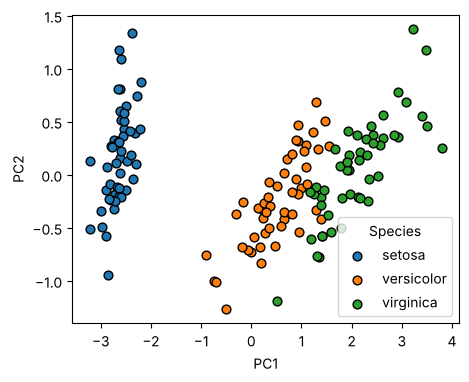

In [11]:
def scatter_by_species(Z, xlabel, ylabel, title=None):
    plt.figure(figsize=(5, 4))
    for s in np.unique(species):
        m = species == s
        plt.scatter(Z[m, 0], Z[m, 1], label=s, edgecolors="k", s=40)
    plt.xlabel(xlabel); plt.ylabel(ylabel); plt.legend(title="Species")
    if title: plt.title(title)
    plt.show()

scatter_by_species(pca.transform(X), "PC1", "PC2")

## Eigenvectors and PCA
PCA is the eigendecomposition of the covariance matrix. The eigenvalues match `pca.explained_variance_`, and the eigenvectors match the loadings (up to sign).

In [12]:
evals, evecs = np.linalg.eigh(np.cov(X, rowvar=False))
order = np.argsort(evals)[::-1]            # eigh returns ascending order
print(evals[order].round(4))
print(pca.explained_variance_.round(4))

[4.2282 0.2427 0.0782 0.0238]
[4.2282 0.2427 0.0782 0.0238]


## Singular value decomposition: test scores
100 students, 24 tests (8 each in math, science, and arts).

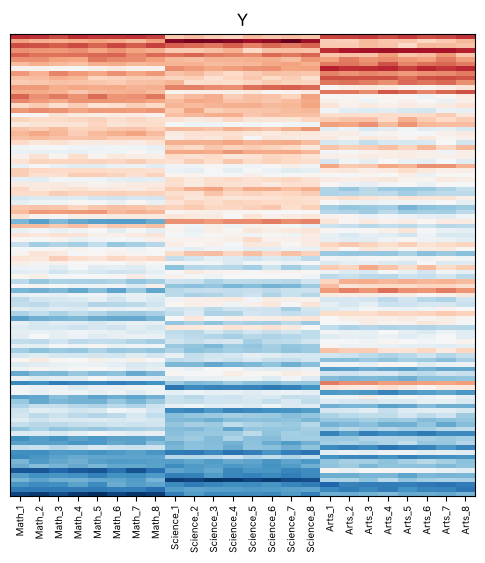

In [13]:
rng = np.random.default_rng(1987)
n, k = 100, 8
Sigma = 64 * np.array([[1, .75, .5], [.75, 1, .5], [.5, .5, 1]])
m = rng.multivariate_normal(np.zeros(3), Sigma, n)
m = m[np.argsort(-m.mean(axis=1))]
y = np.kron(m, np.ones((1, k))) + rng.normal(size=(n, 3 * k))
cols = [f"{s}_{i}" for s in ["Math", "Science", "Arts"] for i in range(1, k + 1)]

def my_image(a, title="", labels=None, zlim=None):
    lim = np.abs(a).max() if zlim is None else zlim
    plt.imshow(a, aspect="auto", cmap="RdBu_r", vmin=-lim, vmax=lim)
    plt.title(title); plt.yticks([])
    if labels is not None:
        plt.xticks(range(len(labels)), labels, rotation=90, fontsize=7)
    else:
        plt.xticks([])

plt.figure(figsize=(6, 6)); my_image(y, "Y", cols); plt.show()

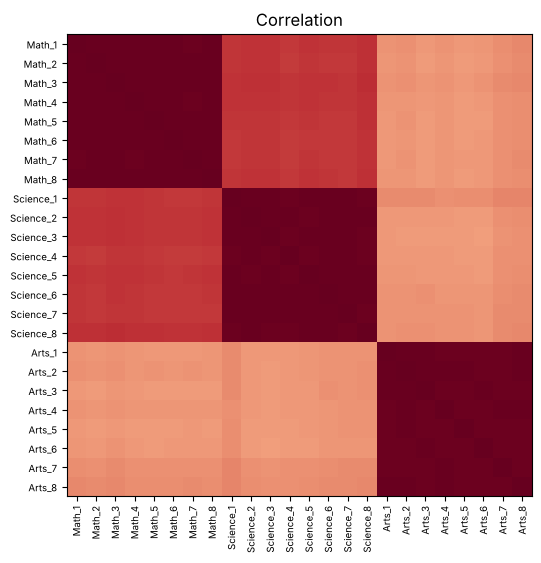

In [14]:
plt.figure(figsize=(6, 6))
my_image(np.corrcoef(y, rowvar=False), "Correlation", cols, zlim=1)
plt.yticks(range(len(cols)), cols, fontsize=7)
plt.show()

`np.linalg.svd` returns $U$, the diagonal of $D$, and $V^\top$ (not $V$). `full_matrices=False` gives the "thin" SVD that R's `svd` returns.

In [15]:
U, d, Vt = np.linalg.svd(y, full_matrices=False)
print(U.shape, d.shape, Vt.shape)

y_svd = U @ np.diag(d) @ Vt
np.abs(y - y_svd).max()

(100, 24) (24,) (24, 24)


np.float64(5.3290705182007514e-14)

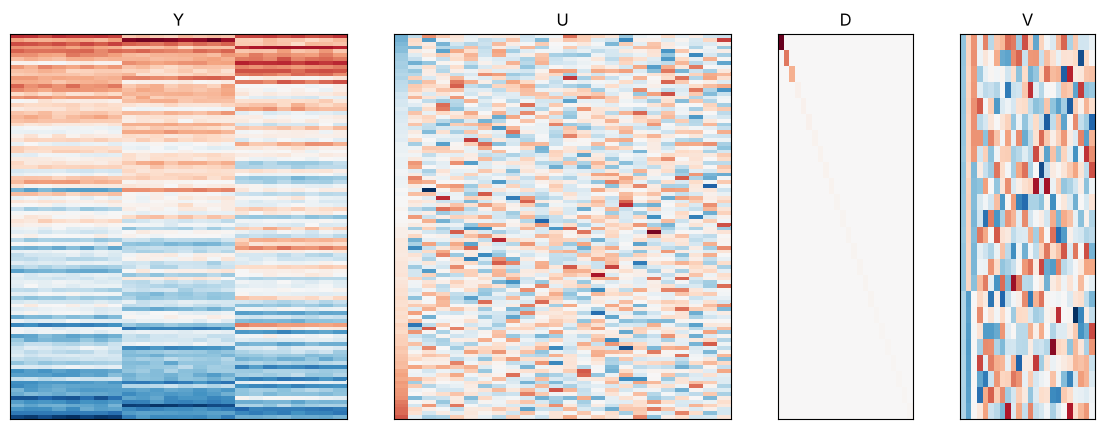

In [16]:
fig, ax = plt.subplots(1, 4, figsize=(14, 5), gridspec_kw={"width_ratios": [3, 3, 1.2, 1.2]})
for a, (mat, t) in zip(ax, [(y, "Y"), (U, "U"), (np.diag(d), "D"), (Vt.T, "V")]):
    plt.sca(a); my_image(mat, t)
plt.show()

Variance explained by each component: $d_j^2 / \sum d_j^2$. Three components (math, science, arts) explain almost everything.

In [17]:
print((d**2 / np.sum(d**2)).round(3)[:6])
print((np.cumsum(d**2) / np.sum(d**2)).round(3)[:6])

[0.701 0.197 0.09  0.001 0.001 0.001]
[0.701 0.897 0.987 0.989 0.99  0.991]


## Non-negative matrix factorization (NMF)
$\mathbf{V} \approx \mathbf{W}\mathbf{H}$. In scikit-learn, `fit_transform` returns $\mathbf{W}$ (R's `basis()`) and `components_` is $\mathbf{H}$ (R's `coef()`). `solver="mu"` is the Lee & Seung multiplicative update algorithm from the slides. scikit-learn doesn't have R's `nrun`, so we loop over seeds and keep the best fit.

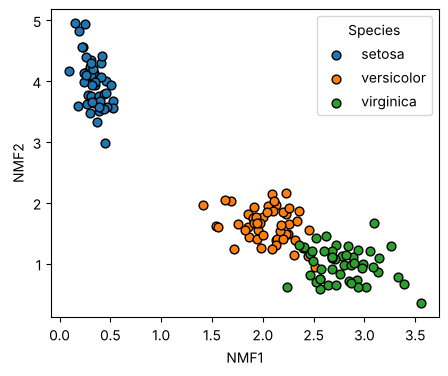

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
NMF1,2.0,0.76,1.92,0.7
NMF2,1.1,0.80,0.21,0.0


In [18]:
best = min((NMF(n_components=2, init="random", solver="mu", max_iter=2000,
                random_state=s).fit(X) for s in range(20)),
           key=lambda f: f.reconstruction_err_)
W = best.transform(X)
H = best.components_
scatter_by_species(W, "NMF1", "NMF2")
pd.DataFrame(H, columns=iris.data.columns, index=["NMF1", "NMF2"]).round(2)

## t-SNE
`perplexity` works the same way as in `Rtsne`. scikit-learn doesn't require removing duplicate rows.

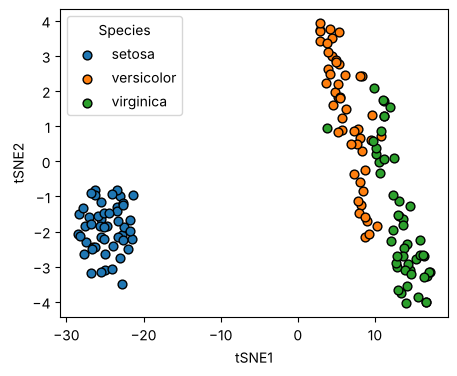

In [19]:
tsne = TSNE(n_components=2, perplexity=30, random_state=1).fit_transform(X)
scatter_by_species(tsne, "tSNE1", "tSNE2")

## UMAP
From the `umap-learn` package (`pip install umap-learn`; imported as `umap`). `n_neighbors` and `min_dist` are the same settings as in R's `uwot::umap`.

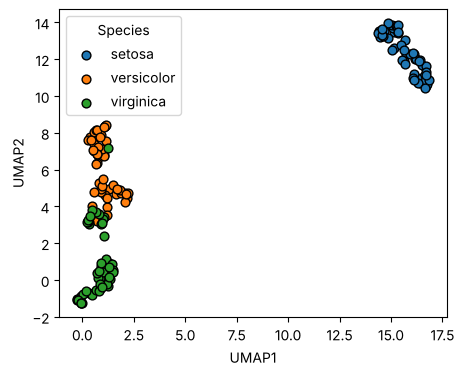

In [20]:
import umap
um = umap.UMAP(n_neighbors=15, random_state=1).fit_transform(X)
scatter_by_species(um, "UMAP1", "UMAP2")

## t-SNE and UMAP on high-dimensional data
With 4 features, iris doesn't really need non-linear methods. The tissue gene expression data (500 genes) is a better example. Common practice: PCA first, then t-SNE/UMAP on the top PCs.

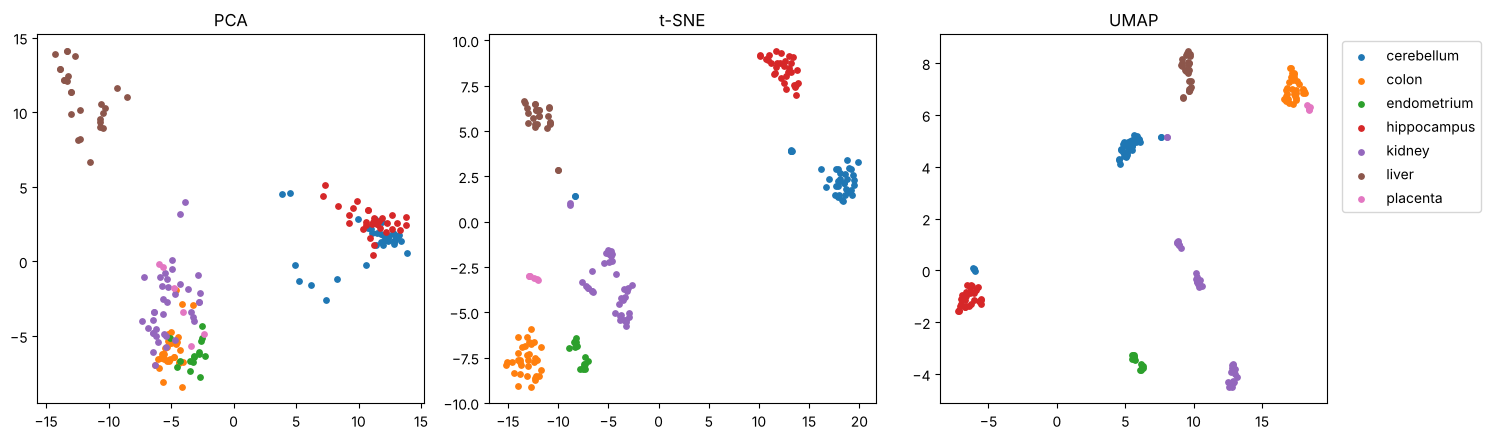

In [21]:
import os
LOCAL = "../data/"
REMOTE = "https://raw.githubusercontent.com/wevanjohnson/2026_Fall_MLBD/main/python/data/"
DATA = LOCAL if os.path.exists(LOCAL) else REMOTE

te = pd.read_csv(DATA + "tissue_gene_expression.csv")
tissue = te.pop("tissue").to_numpy()
top_pcs = PCA(n_components=20).fit_transform(te)

emb = {"PCA": top_pcs[:, :2],
       "t-SNE": TSNE(perplexity=30, random_state=1).fit_transform(top_pcs),
       "UMAP": umap.UMAP(n_neighbors=15, random_state=1).fit_transform(top_pcs)}

fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
for a, (name, E) in zip(ax, emb.items()):
    for t in np.unique(tissue):
        a.scatter(E[tissue == t, 0], E[tissue == t, 1], label=t, s=15)
    a.set_title(name)
ax[2].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()